# Analyze MIBI-TOF image data

(Overall similar to IMC but MIBI uses an ion beam instead of a laser)

### Aim:
Learn how to extract per-cell marker intensities from raw multiplexed images using a cell segmentation mask

### Data:
colorectal cancer biopsies from 3 donors (Hartmann et al., 2020). There are 3 marker images per biopsy: CD45 immune cell in cyan colour, cytokeratin tumour cells in magenta colour and vimentin mesenchymal/stromal cells in yellow colour. 

### Workflow:
1. Load the data and plot the cells
2. Put the images and masks into an ImageContainer
3. Separate the colour channels (CMYK)
4. Calculate each cell's mean intensity
5. Transform the values (arcsinh) and check them against the authors' values

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import squidpy as sq

adata = sq.datasets.mibitof()

/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO     Downloading mibitof.h5ad from https://exampledata.scverse.org/squidpy/mibitof.h5ad                        


100%|█████████████████████████████████████| 20.3M/20.3M [00:00<00:00, 21.4GB/s]


/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in 

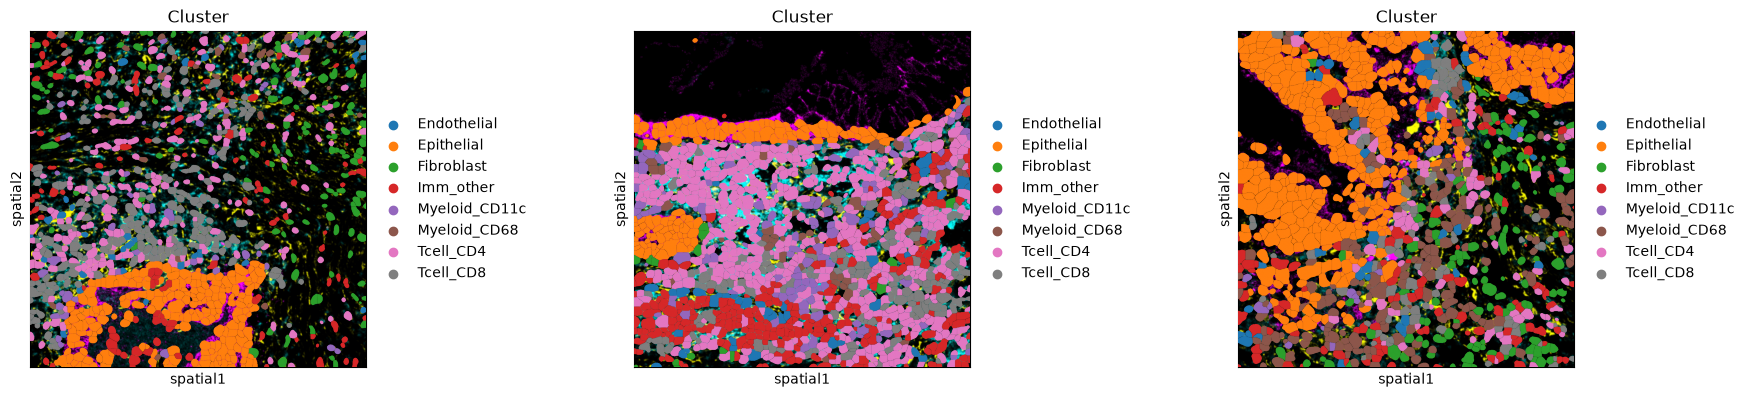

In [ ]:
sq.pl.spatial_segment(adata, color="Cluster", library_key="library_id", seg_cell_id="cell_id")

# spatial_segment draws the actual cell outlines on top of the image, which is more informative than just plotting the cell centroids


## Build an ImageContainer
ImageContainer object to store the images and segmentation masks for each library. y dimension represent rows of pixels (heights) x dimension represents columns of pixels (width) z dimension represent page for each bipsy (origianlly z dimension is for 3D imaging) and each dimensions have 3 colour channels.  

In [5]:
# build 3 separte ImageContainer for each biopsy with picture and cell outlines (mask)
imgs = []
for library_id in adata.uns["spatial"].keys():
    img = sq.im.ImageContainer( # building ImageContainer
        adata.uns["spatial"][library_id]["images"]["hires"], library_id=library_id
    )
    img.add_img( # add masks (cell outlines) to the ImageContainer
        adata.uns["spatial"][library_id]["images"]["segmentation"],
        library_id=library_id,
        layer="segmentation",
    )
    img["segmentation"].attrs["segmentation"] = True
    imgs.append(img)
img = sq.im.ImageContainer.concat(imgs)

img



ImageContainer[shape=(1024, 1024), layers=['image', 'segmentation']]

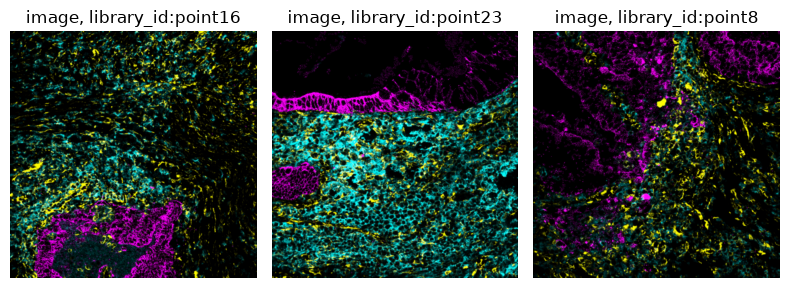

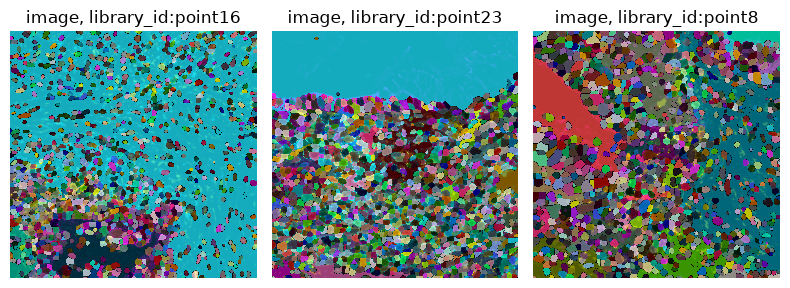

In [6]:
img.show("image")
img.show("image", segmentation_layer="segmentation")

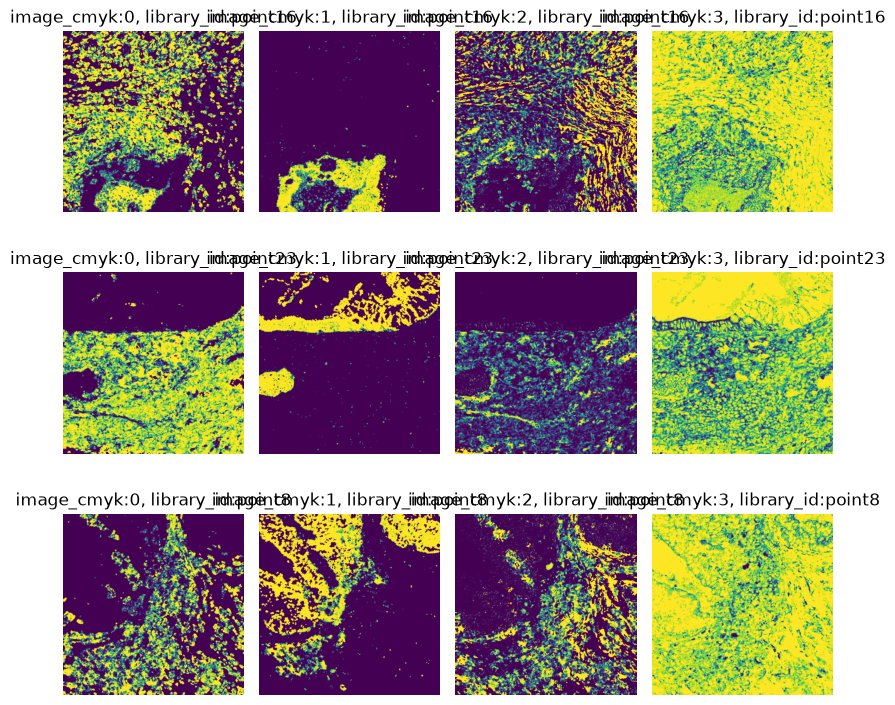

In [ ]:
# Convert the colours (CMYK) - cyan, magenta, yellow, black
# cyan (0, 255, 255), magenta (255, 0, 255), yellow (255, 255, 0), black (0, 0, 0)
# the three markers encoded in the CMYK space therefore we need to covert RGB images to CMYK space to extract the marker intensities
def rgb2cmyk(arr):
    """Convert arr from RGB to CMYK color space."""
    R = arr[..., 0] / 255 # ... means all dimensions except the last one, which is the color channel
    G = arr[..., 1] / 255 # divided by 255 to scale the values between 0 and 1
    B = arr[..., 2] / 255
    K = 1 - (np.max(arr, axis=-1) / 255) # K represent how dark the pixel is on a scale from 0 to 1, K=0 means pure colour
    # 1 - brightest channel from RGB
    C = (1 - R - K) / (1 - K + np.finfo(float).eps)  # avoid division by 0
    M = (1 - G - K) / (1 - K + np.finfo(float).eps)
    Y = (1 - B - K) / (1 - K + np.finfo(float).eps)
    return np.stack([C, M, Y, K], axis=3)


img.apply(rgb2cmyk, layer="image", new_layer="image_cmyk", copy=False)
img.show("image_cmyk", channelwise=True)

In [8]:
# Mean intensity for each cell
# for each cell cut a small square around the cell based on the centroid of the cell in the segmentation mask
# and find which pixels belong to that specific cell in the mask and average the marker values over those pixels
# this prevent other cells from contributing to the mean intensity of the cell of interest
def segmentation_image_intensity(arr, image_cmyk):
    """
    Calculate per-channel mean intensity of the center segment.

    arr: the segmentation
    image_cmyk: the raw image values
    """
    import skimage.measure

    # the center of the segmentation mask contains the current label
    # use that to calculate the mask
    s = arr.shape[0]
    mask = (arr == arr[s // 2, s // 2, 0, 0]).astype(int)
    # use skimage.measure.regionprops to get the intensity per channel
    features = []
    for c in range(image_cmyk.shape[-1]):
        feature = skimage.measure.regionprops_table(
            np.squeeze(mask),  # skimage needs 3d or 2d images, so squeeze excess dims
            intensity_image=np.squeeze(image_cmyk[:, :, :, c]),
            properties=["mean_intensity"],
        )["mean_intensity"][0]
        features.append(feature)
    return features

# for every cell, from this process we get 4 values, one for each channel (C, M, Y, K)
# C for CD45, M for CK, Y for vimentin and K for darkness (not a marker)

In [ ]:
sq.im.calculate_image_features(
    adata,
    img,
    library_id="library_id",
    features="custom",
    spot_scale=10,
    layer="segmentation",
    features_kwargs={
        "custom": {
            "func": segmentation_image_intensity,
            "additional_layers": ["image_cmyk"],
        }
    },
)
adata.obsm["img_features"]

# the column name end with 0 represent cyan CD45,  1 represent magenta CK, 2 represent yellow vimentin and 3 represent black darkness

100%|██████████| 3309/3309 [00:10<00:00, 315.65/s]


,segmentation_image_intensity_0,segmentation_image_intensity_1,segmentation_image_intensity_2,segmentation_image_intensity_3
3034-0,0.000000,0.995041,0.010664,0.492503
3035-0,0.000049,0.884839,0.042991,0.713101
3036-0,0.680350,0.000235,0.222640,0.948284
3037-0,0.813055,0.000000,0.173941,0.790169
3038-0,0.420203,0.015063,0.486171,0.709584
...,...,...,...,...
47342-2,0.000000,0.000000,0.696113,0.855720
47343-2,0.441017,0.000000,0.587986,0.941870
47344-2,0.639157,0.000000,0.344870,0.858989
47345-2,0.196760,0.000000,0.612479,0.855991


In [ ]:
# Transform using an inverse hyperbolic sin (arcsinh) 
# arcsinh is the standard transform for imaging and mass cytometry data
# which squashes the high values and spreads out the low values, making it easier to visualize and analyze the data
# cofactor 0.05 is the separator between low and high values, 
# smaller than cofactor almost unchanged but bigger than cofactor squashed like a log to prevent dominating the analysis by a few high values
# smaller cofactor value represents treating the low values as real signal as well 
adata.obsm["img_features_transformed"] = np.arcsinh(adata.obsm["img_features"] / 0.05)

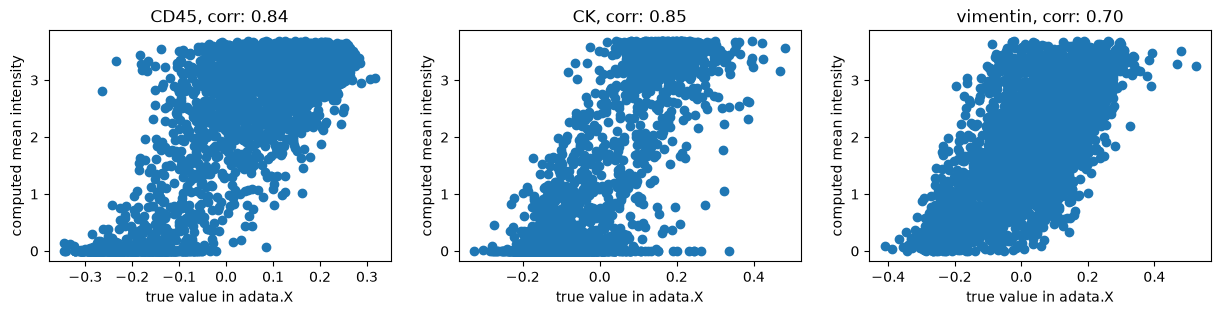

In [ ]:
channels = ["CD45", "CK", "vimentin"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for i, ax in enumerate(axes):
    X = np.array(adata[:, channels[i]].X.todense())[:, 0]
    Y = adata.obsm["img_features_transformed"][f"segmentation_image_intensity_{i}"]
    ax.scatter(X, Y)
    ax.set_xlabel("true value in adata.X")
    ax.set_ylabel("computed mean intensity")
    corr = np.corrcoef(X, Y)[1, 0]
    ax.set_title(f"{channels[i]}, corr: {corr:.2f}")

# the results represent high correlation between true value and computed mean intensity, 
# which means the mean intensity calculation is accurate and reliable